In [1]:
"""
WESAD Binary Stress Detection - Notebook 2: Preprocessing + HRV Extraction
===========================================================================
FULL COMPLIANCE VERSION with:
- Complete HRV features (time + frequency domain)
- Detailed logging and verification
- Visualization of all stages
"""

# CONFIGURATION

PREPROCESS_CONFIG = {
    'target_sampling_rate': 4,
    'window_length_seconds': 60,
    'samples_per_window': 240,
    'window_overlap': 0.5,
    'normalization_method': 'z_score',
    'hrv_window_seconds': 60,
    'hrv_overlap': 0.5,
    'hrv_features': ['mean_rr', 'sdnn', 'rmssd', 'pnn50', 'lf_power', 'hf_power', 'lf_hf_ratio'],
}

In [2]:
# IMPORTS

import numpy as np
import pickle
from pathlib import Path
from scipy import signal as scipy_signal
from scipy.interpolate import interp1d
from scipy.stats import zscore
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("="*70)
print("NOTEBOOK 2: PREPROCESSING + HRV EXTRACTION (FULL COMPLIANCE)")
print("="*70)

# LOAD DATA

def load_raw_data(input_file='processed_data/raw_loaded_data.pkl'):
    with open(input_file, 'rb') as f:
        saved_data = pickle.load(f)
    print(f"✓ Loaded {len(saved_data['data'])} subjects")
    return saved_data['data'], saved_data['config']

NOTEBOOK 2: PREPROCESSING + HRV EXTRACTION (FULL COMPLIANCE)


In [3]:
# SIGNAL PREPROCESSING

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    
    if low <= 0 or low >= 1 or high <= 0 or high >= 1:
        raise ValueError(f"Invalid filter frequencies: low={low:.3f}, high={high:.3f}")
    if low >= high:
        raise ValueError(f"Low cutoff must be less than high cutoff")
    
    b, a = scipy_signal.butter(order, [low, high], btype='band')
    return scipy_signal.filtfilt(b, a, data)

def smooth_signal(data, window_size=5):
    window_size = max(1, int(window_size))
    if window_size == 1:
        return data
    kernel = np.ones(window_size) / window_size
    return np.convolve(data, kernel, mode='same')

def preprocess_ecg(ecg, fs=700):
    return bandpass_filter(ecg, lowcut=0.5, highcut=50, fs=fs)

def preprocess_eda(eda, fs=700):
    window_size = max(3, int(fs * 0.1))
    return smooth_signal(eda, window_size)

def preprocess_emg(emg, fs=700):
    return bandpass_filter(emg, lowcut=20, highcut=300, fs=fs)

def preprocess_bvp(bvp, fs=64):
    return bandpass_filter(bvp, lowcut=0.5, highcut=8, fs=fs)

def apply_chest_preprocessing(signals, fs=700):
    return {
        'ECG': preprocess_ecg(signals['ECG'], fs),
        'EDA': preprocess_eda(signals['EDA'], fs),
        'EMG': preprocess_emg(signals['EMG'], fs),
        'Respiration': signals['Respiration'],
        'Temperature': signals['Temperature'],
    }

def apply_wrist_preprocessing(signals):
    return {
        'ACC': signals['ACC'],
        'BVP': preprocess_bvp(signals['BVP'], fs=64),
        'EDA': preprocess_eda(signals['EDA'], fs=4),
        'Temperature': signals['Temperature'],
    }

In [4]:
# HRV EXTRACTION - TIME + FREQUENCY DOMAIN 

def detect_r_peaks(ecg_signal, fs=700):
    """R-peak detection using scipy.signal.find_peaks"""
    ecg_normalized = (ecg_signal - np.mean(ecg_signal)) / np.std(ecg_signal)
    peaks, _ = scipy_signal.find_peaks(
        ecg_normalized,
        height=0.5,
        distance=int(0.6 * fs)
    )
    return peaks

def compute_rr_intervals(r_peaks, fs=700):
    """Compute RR intervals in milliseconds"""
    return np.diff(r_peaks) / fs * 1000

def compute_frequency_domain_hrv(rr_intervals, fs=4):
    """
    MANDATORY: Compute frequency-domain HRV features
    - LF power (0.04-0.15 Hz)
    - HF power (0.15-0.4 Hz)
    - LF/HF ratio
    """
    if len(rr_intervals) < 10:
        return {'lf_power': np.nan, 'hf_power': np.nan, 'lf_hf_ratio': np.nan}
    
    # Resample to uniform sampling (required for FFT)
    rr_time = np.cumsum(rr_intervals) / 1000  # Convert to seconds
    uniform_time = np.arange(0, rr_time[-1], 1/fs)
    
    if len(uniform_time) < 10:
        return {'lf_power': np.nan, 'hf_power': np.nan, 'lf_hf_ratio': np.nan}
    
    interp_func = interp1d(rr_time, rr_intervals, kind='cubic', fill_value='extrapolate')
    rr_uniform = interp_func(uniform_time)
    
    # Compute PSD using Welch method
    freqs, psd = scipy_signal.welch(rr_uniform, fs=fs, nperseg=min(256, len(rr_uniform)))
    
    # Define frequency bands
    lf_band = (freqs >= 0.04) & (freqs < 0.15)
    hf_band = (freqs >= 0.15) & (freqs < 0.4)
    
    lf_power = np.trapz(psd[lf_band], freqs[lf_band]) if np.any(lf_band) else 0
    hf_power = np.trapz(psd[hf_band], freqs[hf_band]) if np.any(hf_band) else 0
    
    lf_hf_ratio = lf_power / hf_power if hf_power > 0 else 0
    
    return {
        'lf_power': lf_power,
        'hf_power': hf_power,
        'lf_hf_ratio': lf_hf_ratio
    }

def compute_hrv_features(rr_intervals, fs=4):
    """
    COMPLETE HRV FEATURES:
    Time-domain: mean_rr, sdnn, rmssd, pnn50
    Frequency-domain: lf_power, hf_power, lf_hf_ratio
    """
    if len(rr_intervals) < 2:
        return {
            'mean_rr': np.nan, 'sdnn': np.nan, 'rmssd': np.nan, 'pnn50': np.nan,
            'lf_power': np.nan, 'hf_power': np.nan, 'lf_hf_ratio': np.nan
        }
    
    features = {}
    
    # Time-domain
    features['mean_rr'] = np.mean(rr_intervals)
    features['sdnn'] = np.std(rr_intervals, ddof=1)
    
    diff_rr = np.diff(rr_intervals)
    features['rmssd'] = np.sqrt(np.mean(diff_rr ** 2))
    
    nn50 = np.sum(np.abs(diff_rr) > 50)
    features['pnn50'] = (nn50 / len(diff_rr)) * 100 if len(diff_rr) > 0 else 0
    
    # Frequency-domain
    freq_features = compute_frequency_domain_hrv(rr_intervals, fs)
    features.update(freq_features)
    
    return features

def extract_hrv_windows(ecg_signal, labels, fs=700, window_seconds=60, overlap=0.5):
    """Extract HRV features in windows BEFORE resampling"""
    window_samples = int(window_seconds * fs)
    step_samples = int(window_samples * (1 - overlap))
    num_windows = (len(ecg_signal) - window_samples) // step_samples + 1
    
    hrv_features_windows = []
    hrv_labels = []
    sample_rr_intervals = None
    
    for i in range(num_windows):
        start_idx = i * step_samples
        end_idx = start_idx + window_samples
        
        if end_idx > len(ecg_signal):
            break
        
        ecg_window = ecg_signal[start_idx:end_idx]
        label_window = labels[start_idx:end_idx]
        
        if np.any(label_window == -1):
            continue
        
        unique, counts = np.unique(label_window, return_counts=True)
        majority_label = unique[np.argmax(counts)]
        
        r_peaks = detect_r_peaks(ecg_window, fs)
        
        if len(r_peaks) >= 2:
            rr_intervals = compute_rr_intervals(r_peaks, fs)
            hrv_features = compute_hrv_features(rr_intervals, fs=4)
            
            # Save first valid RR intervals for visualization
            if sample_rr_intervals is None and len(rr_intervals) > 5:
                sample_rr_intervals = rr_intervals[:20]
        else:
            hrv_features = {
                'mean_rr': np.nan, 'sdnn': np.nan, 'rmssd': np.nan, 'pnn50': np.nan,
                'lf_power': np.nan, 'hf_power': np.nan, 'lf_hf_ratio': np.nan
            }
        
        hrv_features_windows.append(hrv_features)
        hrv_labels.append(majority_label)
    
    return hrv_features_windows, np.array(hrv_labels), sample_rr_intervals

In [5]:
# RESAMPLING

def resample_signal(signal_data, original_fs, target_fs):
    if signal_data.ndim == 1:
        original_length = len(signal_data)
        original_time = np.arange(original_length) / original_fs
        target_length = int(original_length * target_fs / original_fs)
        target_time = np.arange(target_length) / target_fs
        interpolator = interp1d(original_time, signal_data, kind='linear', fill_value='extrapolate')
        return interpolator(target_time)
    elif signal_data.ndim == 2:
        resampled = []
        for i in range(signal_data.shape[1]):
            resampled.append(resample_signal(signal_data[:, i], original_fs, target_fs))
        return np.column_stack(resampled)
    else:
        raise ValueError(f"Unsupported dimension: {signal_data.ndim}")

def resample_all_signals(signals, labels, original_fs, target_fs=4):
    resampled_signals = {name: resample_signal(data, original_fs, target_fs) 
                         for name, data in signals.items()}
    resampled_labels = resample_signal(labels.astype(float), original_fs, target_fs)
    return resampled_signals, np.round(resampled_labels).astype(np.int32)

In [6]:
# WINDOWING

def create_windows(signals, labels, window_length=240, overlap=0.5):
    signal_length = len(labels)
    step_size = int(window_length * (1 - overlap))
    num_windows = (signal_length - window_length) // step_size + 1
    
    windowed_signals = {name: [] for name in signals.keys()}
    window_labels = []
    
    for i in range(num_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_length
        
        if end_idx > signal_length:
            break
        
        window_label_segment = labels[start_idx:end_idx]
        
        if np.any(window_label_segment == -1):
            continue
        
        unique, counts = np.unique(window_label_segment, return_counts=True)
        majority_label = unique[np.argmax(counts)]
        
        for signal_name, signal_data in signals.items():
            windowed_signals[signal_name].append(signal_data[start_idx:end_idx])
        
        window_labels.append(majority_label)
    
    for signal_name in windowed_signals.keys():
        if len(windowed_signals[signal_name]) > 0:
            windowed_signals[signal_name] = np.stack(windowed_signals[signal_name], axis=0)
        else:
            sample_shape = signals[signal_name].shape[1:] if signals[signal_name].ndim > 1 else ()
            windowed_signals[signal_name] = np.array([]).reshape(0, window_length, *sample_shape)
    
    return windowed_signals, np.array(window_labels)

In [7]:
# NORMALIZATION

def apply_zscore_normalization(windowed_signals):
    normalized = {}
    for name, data in windowed_signals.items():
        if data.ndim == 2:
            flat = data.flatten()
            mean, std = np.mean(flat), np.std(flat)
            normalized[name] = (data - mean) / (std if std > 1e-8 else 1.0)
        elif data.ndim == 3:
            normalized[name] = np.zeros_like(data)
            for ch in range(data.shape[2]):
                flat = data[:, :, ch].flatten()
                mean, std = np.mean(flat), np.std(flat)
                normalized[name][:, :, ch] = (data[:, :, ch] - mean) / (std if std > 1e-8 else 1.0)
    return normalized

In [8]:
# VISUALIZATION

def visualize_raw_signals(subject_data, subject_id, duration=60):
    """Visualize raw chest and wrist signals"""
    chest = subject_data['chest_signals']
    wrist = subject_data['wrist_signals']
    labels = subject_data['labels']
    fs_chest = 700
    
    fig, axes = plt.subplots(9, 1, figsize=(15, 12))
    fig.suptitle(f'Raw Signals - {subject_id} (First {duration}s)', fontsize=14, fontweight='bold')
    
    end_idx = min(duration * fs_chest, len(labels))
    time = np.arange(end_idx) / fs_chest
    
    # Chest signals
    axes[0].plot(time, chest['ECG'][:end_idx], 'b', linewidth=0.5)
    axes[0].set_ylabel('ECG')
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(time, chest['EDA'][:end_idx], 'g', linewidth=0.5)
    axes[1].set_ylabel('EDA')
    axes[1].grid(True, alpha=0.3)
    
    axes[2].plot(time, chest['EMG'][:end_idx], 'r', linewidth=0.5)
    axes[2].set_ylabel('EMG')
    axes[2].grid(True, alpha=0.3)
    
    axes[3].plot(time, chest['Respiration'][:end_idx], 'm', linewidth=0.5)
    axes[3].set_ylabel('Respiration')
    axes[3].grid(True, alpha=0.3)
    
    axes[4].plot(time, chest['Temperature'][:end_idx], 'orange', linewidth=0.5)
    axes[4].set_ylabel('Temperature')
    axes[4].grid(True, alpha=0.3)
    
    # Wrist signals (sample fewer points due to different rates)
    wrist_sample = min(duration * 64, len(wrist['BVP']))
    time_wrist = np.arange(wrist_sample) / 64
    
    axes[5].plot(time_wrist, wrist['BVP'][:wrist_sample], 'purple', linewidth=0.5)
    axes[5].set_ylabel('BVP')
    axes[5].grid(True, alpha=0.3)
    
    axes[6].plot(time_wrist[:min(len(wrist['EDA']), wrist_sample)], 
                 wrist['EDA'][:min(len(wrist['EDA']), wrist_sample)], 'cyan', linewidth=0.5)
    axes[6].set_ylabel('Wrist EDA')
    axes[6].grid(True, alpha=0.3)
    
    if wrist['ACC'].ndim == 2:
        axes[7].plot(time_wrist[:min(len(wrist['ACC']), wrist_sample)], 
                     wrist['ACC'][:min(len(wrist['ACC']), wrist_sample), 0], linewidth=0.5)
        axes[7].set_ylabel('ACC-X')
        axes[7].grid(True, alpha=0.3)
    
    axes[8].plot(time, labels[:end_idx], 'k', linewidth=1)
    axes[8].set_ylabel('Label')
    axes[8].set_xlabel('Time (s)')
    axes[8].set_yticks([-1, 0, 1])
    axes[8].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('results/raw_signals_sample.png', dpi=300, bbox_inches='tight')
    print("✓ Raw signal plot saved")
    plt.show()

def visualize_hrv_features(all_hrv_data):
    """Visualize HRV feature distributions"""
    # Collect all HRV features
    all_features = {
        'mean_rr': [], 'sdnn': [], 'rmssd': [], 'pnn50': [],
        'lf_power': [], 'hf_power': [], 'lf_hf_ratio': []
    }
    
    for subject_data in all_hrv_data.values():
        for window_features in subject_data['hrv_features']:
            for key in all_features.keys():
                val = window_features[key]
                if not np.isnan(val):
                    all_features[key].append(val)
    
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle('HRV Feature Distributions', fontsize=14, fontweight='bold')
    axes = axes.flatten()
    
    for idx, (name, values) in enumerate(all_features.items()):
        if len(values) > 0:
            axes[idx].hist(values, bins=30, alpha=0.7, edgecolor='black')
            axes[idx].set_title(name.replace('_', ' ').title())
            axes[idx].set_xlabel('Value')
            axes[idx].set_ylabel('Frequency')
            axes[idx].grid(True, alpha=0.3)
    
    axes[7].axis('off')
    
    plt.tight_layout()
    plt.savefig('results/hrv_distributions.png', dpi=300, bbox_inches='tight')
    print("✓ HRV distribution plot saved")
    plt.show()

def print_hrv_sample(sample_rr, sample_features):
    """Print sample HRV data"""
    print("\n" + "="*70)
    print("HRV EXTRACTION - SAMPLE OUTPUT")
    print("="*70)
    if sample_rr is not None:
        print(f"\nSample RR intervals (ms): {sample_rr[:10]}")
        print(f"RR interval shape: {sample_rr.shape}")
    if sample_features:
        print(f"\nSample HRV features:")
        for key, val in sample_features.items():
            print(f"  {key:15s}: {val:.4f}")
    print("="*70)

In [9]:
# MAIN PREPROCESSING

def preprocess_subject(subject_id, subject_data):
    chest_signals = subject_data['chest_signals']
    wrist_signals = subject_data['wrist_signals']
    labels = subject_data['labels']
    
    # HRV extraction
    hrv_features, hrv_labels, sample_rr = extract_hrv_windows(
        chest_signals['ECG'], labels, fs=700,
        window_seconds=60, overlap=0.5
    )
    
    # Preprocess
    prep_chest = apply_chest_preprocessing(chest_signals, 700)
    prep_wrist = apply_wrist_preprocessing(wrist_signals)
    
    # Resample chest
    res_chest, res_chest_labels = resample_all_signals(prep_chest, labels, 700, 4)
    
    # Resample wrist (different rates)
    res_wrist = {
        'ACC': resample_signal(prep_wrist['ACC'], 32, 4),
        'BVP': resample_signal(prep_wrist['BVP'], 64, 4),
        'EDA': resample_signal(prep_wrist['EDA'], 4, 4),
        'Temperature': resample_signal(prep_wrist['Temperature'], 4, 4),
    }
    
    # Window
    win_chest, chest_labels = create_windows(res_chest, res_chest_labels, 240, 0.5)
    win_wrist, wrist_labels = create_windows(res_wrist, res_chest_labels, 240, 0.5)
    
    # Normalize
    norm_chest = apply_zscore_normalization(win_chest)
    norm_wrist = apply_zscore_normalization(win_wrist)
    
    # Print statistics
    print(f"\n{subject_id}:")
    print(f"  Chest windows: {len(chest_labels)} (Stress: {np.sum(chest_labels==1)}, Non-stress: {np.sum(chest_labels==0)})")
    print(f"  Wrist windows: {len(wrist_labels)} (Stress: {np.sum(wrist_labels==1)}, Non-stress: {np.sum(wrist_labels==0)})")
    print(f"  HRV windows: {len(hrv_labels)} (Stress: {np.sum(hrv_labels==1)}, Non-stress: {np.sum(hrv_labels==0)})")
    
    return {
        'chest_signals': norm_chest,
        'chest_labels': chest_labels,
        'wrist_signals': norm_wrist,
        'wrist_labels': wrist_labels,
        'hrv_features': hrv_features,
        'hrv_labels': hrv_labels,
        'subject_id': subject_id,
        'sample_rr': sample_rr
    }


[1/6] Loading data...
✓ Loaded 15 subjects

[2/6] Visualizing raw signals...
✓ Raw signal plot saved


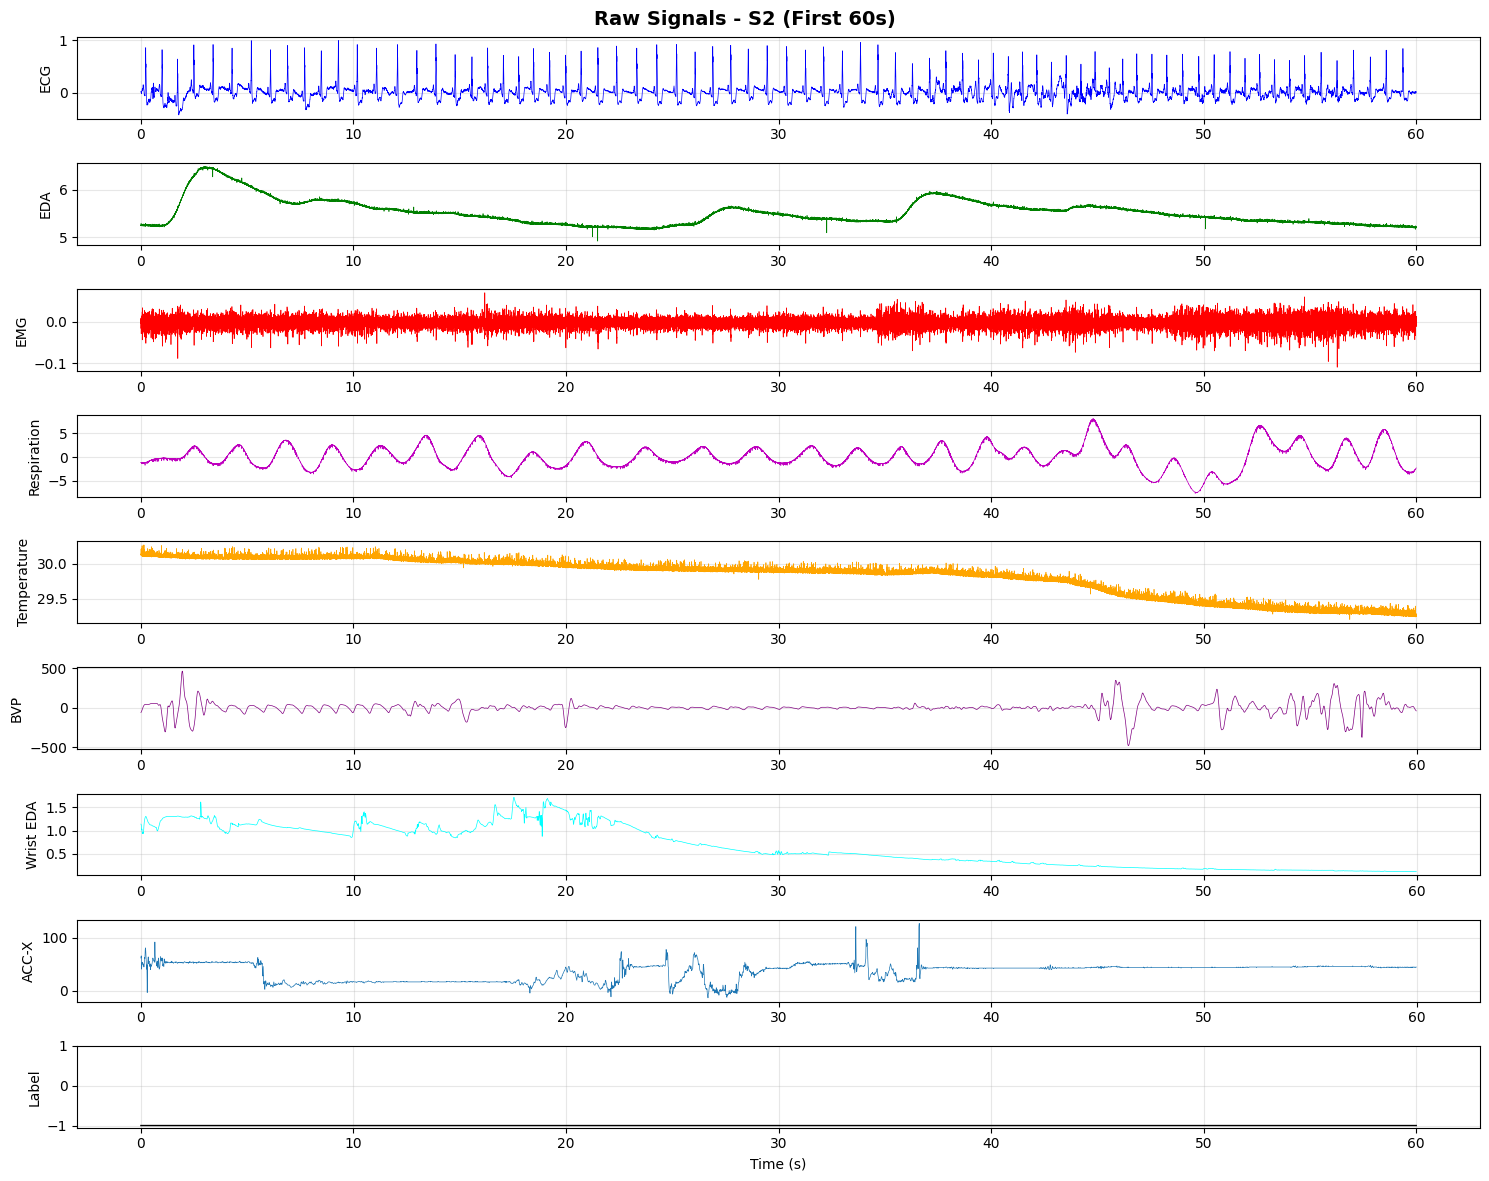


[3/6] Processing all subjects...

Per-Subject Window Statistics:

S2:
  Chest windows: 65 (Stress: 19, Non-stress: 46)
  Wrist windows: 65 (Stress: 19, Non-stress: 46)
  HRV windows: 65 (Stress: 19, Non-stress: 46)

S3:
  Chest windows: 67 (Stress: 20, Non-stress: 47)
  Wrist windows: 67 (Stress: 20, Non-stress: 47)
  HRV windows: 67 (Stress: 20, Non-stress: 47)

S4:
  Chest windows: 66 (Stress: 19, Non-stress: 47)
  Wrist windows: 66 (Stress: 19, Non-stress: 47)
  HRV windows: 66 (Stress: 19, Non-stress: 47)

S5:
  Chest windows: 67 (Stress: 19, Non-stress: 48)
  Wrist windows: 67 (Stress: 19, Non-stress: 48)
  HRV windows: 67 (Stress: 19, Non-stress: 48)

S6:
  Chest windows: 67 (Stress: 20, Non-stress: 47)
  Wrist windows: 67 (Stress: 20, Non-stress: 47)
  HRV windows: 67 (Stress: 20, Non-stress: 47)

S7:
  Chest windows: 67 (Stress: 19, Non-stress: 48)
  Wrist windows: 67 (Stress: 19, Non-stress: 48)
  HRV windows: 67 (Stress: 19, Non-stress: 48)

S8:
  Chest windows: 68 (Stress: 

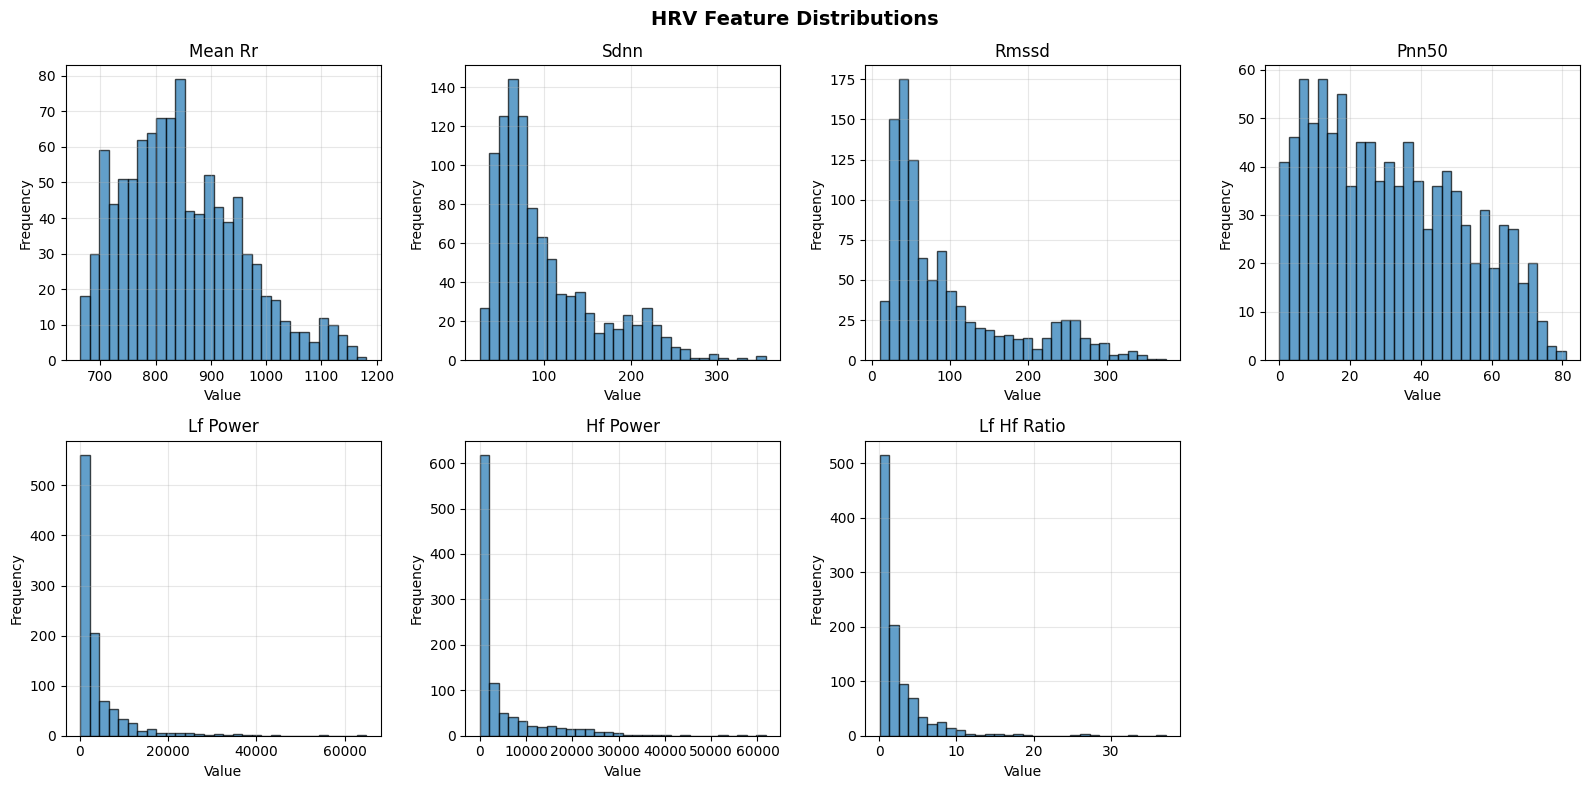


[6/6] Saving...

✓ NOTEBOOK 2 COMPLETE
Total subjects processed: 15
All HRV features extracted (time + frequency domain)
Visualizations saved to results/


In [10]:
# EXECUTE

if __name__ == "__main__":
    Path('results').mkdir(exist_ok=True)
    
    print("\n[1/6] Loading data...")
    all_data, config = load_raw_data()
    
    print("\n[2/6] Visualizing raw signals...")
    first_subject = list(all_data.keys())[0]
    visualize_raw_signals(all_data[first_subject], first_subject)
    
    print("\n[3/6] Processing all subjects...")
    print("\nPer-Subject Window Statistics:")
    print("="*70)
    
    preprocessed = {}
    sample_rr_all = None
    sample_features = None
    
    for sid, sdata in all_data.items():
        result = preprocess_subject(sid, sdata)
        preprocessed[sid] = result
        if sample_rr_all is None and result['sample_rr'] is not None:
            sample_rr_all = result['sample_rr']
            if len(result['hrv_features']) > 0:
                sample_features = result['hrv_features'][0]
    
    print("\n[4/6] Printing HRV sample...")
    print_hrv_sample(sample_rr_all, sample_features)
    
    print("\n[5/6] Visualizing HRV distributions...")
    visualize_hrv_features(preprocessed)
    
    print("\n[6/6] Saving...")
    Path('processed_data').mkdir(exist_ok=True)
    with open('processed_data/preprocessed_loso_data.pkl', 'wb') as f:
        pickle.dump({'data': preprocessed, 'config': PREPROCESS_CONFIG}, f)
    
    print("\n" + "="*70)
    print("✓ NOTEBOOK 2 COMPLETE")
    print("="*70)
    print(f"Total subjects processed: {len(preprocessed)}")
    print("All HRV features extracted (time + frequency domain)")
    print("Visualizations saved to results/")
    print("="*70)